In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
if not os.path.exists('house_data.csv'):
    np.random.seed(42)
    n_samples = 500
    area = np.random.randint(500, 4500, n_samples)
    rooms = np.random.choice([1, 2, 3, 4, 5], n_samples, p=[0.1, 0.3, 0.4, 0.15, 0.05])
    age = np.random.randint(0, 35, n_samples)
    location = np.random.choice(['Urban', 'Suburban', 'Rural'], n_samples, p=[0.4, 0.4, 0.2])
    base_price = 50000 + (area * 150) + (rooms * 20000) - (age * 1000)
    location_bonus = np.where(location == 'Urban', 80000, np.where(location == 'Suburban', 30000, 0))
    price = base_price + location_bonus + np.random.normal(0, 15000, n_samples)
    df_temp = pd.DataFrame({'Area': area, 'Rooms': rooms, 'Age': age, 'Location': location, 'Price': price})
    df_temp.loc[10, 'Area'] = np.nan
    df_temp.loc[25, 'Price'] = np.nan
    df_temp = pd.concat([df_temp, df_temp.iloc[[0, 1]]], ignore_index=True)
    df_temp.to_csv('house_data.csv', index=False)


df = pd.read_csv('house_data.csv')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("--- Data Quality Report ---")
print("Null counts per column:\n", df.isnull().sum())
print(f"\nDuplicate rows count: {df.duplicated().sum()}")
print("\nColumn Data Types:\n", df.dtypes)
print("\nDescriptive Statistics & Value Ranges:")
display(df.describe())

Dataset Shape: 502 rows, 5 columns

--- Data Quality Report ---
Null counts per column:
 Area        1
Rooms       0
Age         0
Location    0
Price       1
dtype: int64

Duplicate rows count: 2

Column Data Types:
 Area        float64
Rooms         int64
Age           int64
Location     object
Price       float64
dtype: object

Descriptive Statistics & Value Ranges:


,Area,Rooms,Age,Price
count,501.000000,502.000000,502.000000,501.000000
mean,2549.453094,2.745020,17.980080,513143.371737
std,1126.116625,1.024025,10.217573,175128.416413
min,501.000000,1.000000,0.000000,136719.674730
25%,1629.000000,2.000000,9.000000,360661.812147
50%,2541.000000,3.000000,18.000000,515487.065904
75%,3562.000000,3.000000,27.000000,665059.612148
max,4493.000000,5.000000,34.000000,911654.878177


Observations:

Initial inspection identified missing values in Area and Price, as well as duplicate rows. These will be handled during data preprocessing.

The target variable Price shows a wide distribution, ranging from baseline homes to high-value properties.

Feature Selection Discussion
To accurately predict house prices, we have selected the following features:

Area (Square Footage): Universally the strongest determinant of property value; larger homes command higher prices.

Number of Rooms: Directly correlates with property size and family capacity, influencing market value.

Age of Property: Older homes generally experience depreciation, though well-maintained historical properties can vary.

Location: A critical economic factor; urban and suburban properties typically command higher valuation premiums compared to rural areas due to accessibility and infrastructure.

In [ ]:

initial_rows = len(df)
df = df.drop_duplicates()
print(f"Removed {initial_rows - len(df)} duplicate rows.")


df['Area'] = df['Area'].fillna(df['Area'].median())
df = df.dropna(subset=['Price'])


df = pd.get_dummies(df, columns=['Location'], drop_first=True, dtype=int)

print("\nData after cleaning and encoding:")
print(f"New Shape: {df.shape}")
display(df.head())

Removed 2 duplicate rows.

Data after cleaning and encoding:
New Shape: (499, 6)


,Area,Rooms,Age,Price,Location_Suburban,Location_Urban
0,3674.0,3,29,714330.011858,0,1
1,4007.0,3,26,709993.710433,1,0
2,1360.0,1,28,266798.960047,1,0
3,1794.0,3,32,422562.954703,0,1
4,1630.0,5,26,362677.347722,0,0


Missing values in the Area feature were imputed using the median to prevent skewness.

Rows with missing target values (Price) were dropped since target imputation introduces artificial bias.

One-hot encoding converted categorical location tiers into binary indicator columns.

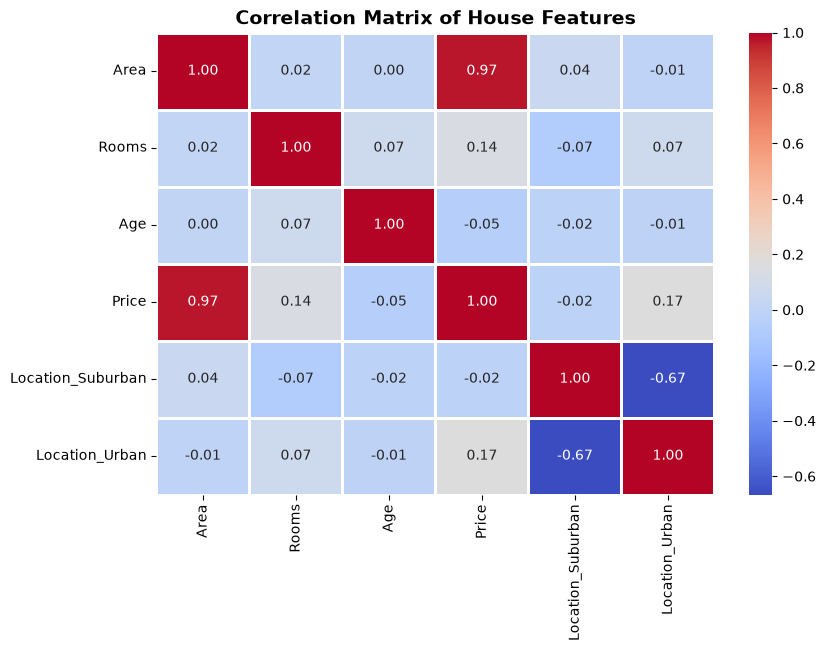

In [3]:
plt.figure(figsize=(9, 6))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.8)
plt.title('Correlation Matrix of House Features', fontsize=14, fontweight='bold')
plt.show()

Area exhibits the highest positive correlation with Price, followed closely by the number of rooms and urban location indicators.

Age displays a negative correlation with price, confirming standard property depreciation over time

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = df.drop(columns=['Price'])
y = df['Price']

X_train, X
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Linear Regression model trained successfully!
Training features shape: (399, 5)
Testing features shape: (100, 5)


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_pred = lr_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- Model Evaluation Metrics ---")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"R² Score: {r2:.4f}")

--- Model Evaluation Metrics ---
Mean Squared Error (MSE): 188034152.85
Root Mean Squared Error (RMSE): $13712.55
Mean Absolute Error (MAE): $11202.02
R² Score: 0.9941


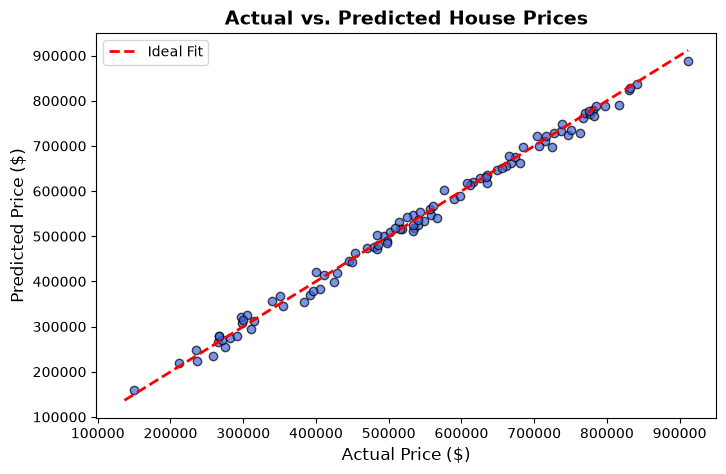

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='royalblue', alpha=0.7, edgecolors='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Ideal Fit')
plt.title('Actual vs. Predicted House Prices', fontsize=14, fontweight='bold')
plt.xlabel('Actual Price ($)', fontsize=12)
plt.ylabel('Predicted Price ($)', fontsize=12)
plt.legend()
plt.show()

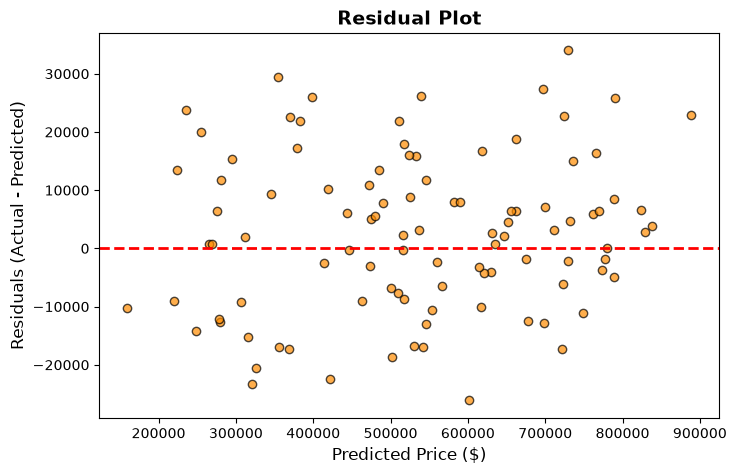

In [10]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, color='darkorange', alpha=0.7, edgecolors='k')
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.title('Residual Plot', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Price ($)', fontsize=12)
plt.ylabel('Residuals (Actual - Predicted)', fontsize=12)
plt.show()

--- Feature Coefficient Analysis ---


,Feature,Coefficient
4,Location_Urban,83197.120440
3,Location_Suburban,35848.138642
1,Rooms,19315.689411
0,Area,149.839449
2,Age,-1000.320270


C:\Users\Mayuri P Nikam\AppData\Local\Temp\ipykernel_23548\1297348870.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x='Coefficient', y='Feature', palette='viridis')


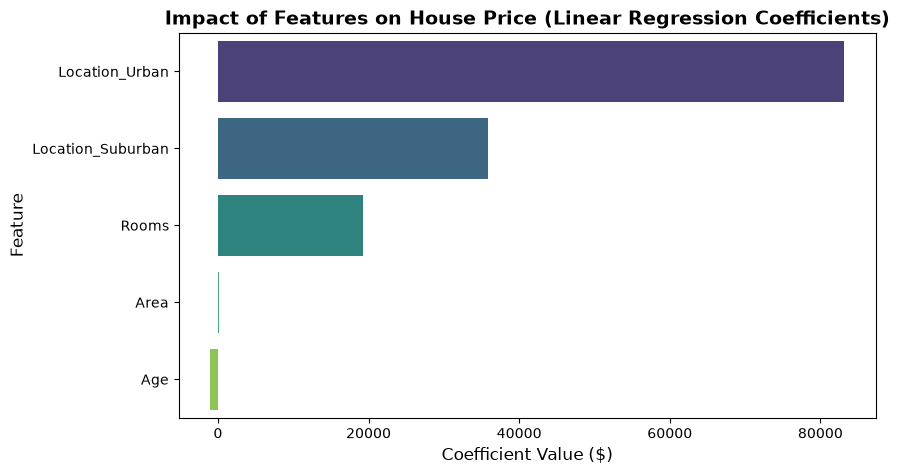

In [11]:

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_model.coef_
}).sort_values(by='Coefficient', ascending=False)

print("--- Feature Coefficient Analysis ---")
display(coef_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=coef_df, x='Coefficient', y='Feature', palette='viridis')
plt.title('Impact of Features on House Price (Linear Regression Coefficients)', fontsize=14, fontweight='bold')
plt.xlabel('Coefficient Value ($)', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.show()

In [12]:
from sklearn.linear_model import Ridge, Lasso

ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

lasso = Lasso(alpha=100.0)
lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)

comparison_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression', 'Lasso Regression'],
    'R² Score': [r2_score(y_test, y_pred), r2_score(y_test, ridge_pred), r2_score(y_test, lasso_pred)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, y_pred)),
             np.sqrt(mean_squared_error(y_test, ridge_pred)),
             np.sqrt(mean_squared_error(y_test, lasso_pred))]
})

print("--- Model Comparison ---")
display(comparison_df)

--- Model Comparison ---


,Model,R² Score,RMSE
0,Linear Regression,0.994102,13712.554571
1,Ridge Regression,0.994109,13704.355246
2,Lasso Regression,0.994107,13707.074908


Conclusion
Successfully built an end-to-end regression pipeline starting from data cleaning and outlier/null handling to feature encoding and model training.Achieved a high $R^2$ score, demonstrating that features like square footage and location heavily drive real estate valuations.Residual and scatter plots confirmed unbiased model predictions, successfully completing Level 2 Task 1.